# Lab 2 — What Did the Campaign Deliver?
Name: Dzhura Daryna | Group: КМ-41

## Setup

In [29]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

# Persons = R and L only
valid_respondent_ids = set(daily_weights[daily_weights['resp_type'].isin(['R', 'L'])]['respondent_id'])

# Demographics by attr_id (see the attributes table)
AGE_18_49 = [318, 321, 325, 335]   # 18-20, 21-24, 25-34, 35-49
AGE_18_34 = [318, 321, 325]        # 18-20, 21-24, 25-34
FEMALE = [202]

def ids_with(attr_ids):
    got = viewer_attributes[viewer_attributes['attr_id'].isin(attr_ids)]['respondent_id']
    return set(got) & valid_respondent_ids

a18_49_ids = ids_with(AGE_18_49)
w18_34_ids = ids_with(FEMALE) & ids_with(AGE_18_34)   # intersection

# Weights: monthly weight = average weight over in-tab days
daily_weights_valid = daily_weights[daily_weights['respondent_id'].isin(valid_respondent_ids)].copy()
monthly_weights = daily_weights_valid.groupby('respondent_id')['weight'].mean().to_dict()
pop_monthly_p2 = sum(monthly_weights.values())
pop_monthly_a1849 = sum(monthly_weights[r] for r in a18_49_ids if r in monthly_weights)

viewings_valid = viewings[viewings['respondent_id'].isin(valid_respondent_ids)].copy()

print("Setup completed successfully!")
print("Total valid panelists:", len(valid_respondent_ids))
print("A18-49 panelists:", len(a18_49_ids))
print("W18-34 panelists:", len(w18_34_ids))
print("A18-49 share of P2+:", round(pop_monthly_a1849 / pop_monthly_p2, 3))   # expect about 0.42

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.
Setup completed successfully!
Total valid panelists: 10210
A18-49 panelists: 4568
W18-34 panelists: 1047
A18-49 share of P2+: 0.422


## Task 1.1 — Size

In [30]:
print("Spots:", len(commercials))
print("Pods:", commercials['pod_id'].nunique())
print("Brands:", commercials['brand'].nunique())
print("Categories:", commercials['category'].nunique())

brand_a_spots = commercials[commercials['brand'] == 'BRAND_A'].copy()
print("BRAND_A spots:", len(brand_a_spots))

brand_a_by_net = brand_a_spots.groupby('network_code').size().reset_index(name='spots_count')
display(brand_a_by_net)

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300


,network_code,spots_count
0,ABC,29
1,BRAVO,33
2,CBS,22
3,FNC,40
4,FOOD,33
5,FOX,13
6,FX,38
7,HGTV,39
8,HIST,37
9,NBC,16


## Task 1.2 — Ad load

In [31]:
comm_load = commercials.copy()
comm_load['clock_hour'] = comm_load['start_ts'].dt.floor('h')
hourly_load = comm_load.groupby(['network_code', 'clock_hour'])['length_sec'].sum().reset_index()
avg_ad = hourly_load.groupby('network_code')['length_sec'].mean().reset_index()
avg_ad['ad_minutes_per_hour'] = avg_ad['length_sec'] / 60.0
avg_ad = avg_ad[['network_code', 'ad_minutes_per_hour']].sort_values('ad_minutes_per_hour', ascending=False)
display(avg_ad.style.format({'ad_minutes_per_hour': '{:.1f}'}))
print("Heaviest ad load:", avg_ad.iloc[0]['network_code'])

,network_code,ad_minutes_per_hour
3,FNC,15.6
1,BRAVO,13.4
7,HGTV,13.3
8,HIST,13.2
4,FOOD,13.1
6,FX,12.9
2,CBS,12.1
0,ABC,11.8
9,NBC,11.8
5,FOX,11.8


Heaviest ad load: FNC


**Answer:** The broadcast networks (CBS, NBC, ABC, FOX) work through local affiliate stations. In local-station hours, such as local morning or evening news, the ad breaks are sold locally by the stations, not nationally by the network. These spots are not in the national ad log, so those hours contain no national ads. The heaviest ad load is on FNC, about 15.6 minutes per hour.

## Task 1.3 — Price everything

In [32]:
comm_priced = commercials.merge(programs[['telecast_id', 'program_name']], on='telecast_id', how='left')

# Broadcast clock: shift by 6 hours
b_ts = comm_priced['start_ts'] - pd.Timedelta(hours=6)
comm_priced['broadcast_weekday'] = b_ts.dt.weekday
comm_priced['b_mins'] = b_ts.dt.hour * 60 + b_ts.dt.minute

def to_b_mins(t):
    hh, mm = map(int, str(t).split(':'))
    return hh * 60 + mm - 360

has_prog = rate_card['program_name'].notna() & (rate_card['program_name'] != '')
rc_program = rate_card[has_prog].copy()
rc_time = rate_card[~has_prog].copy()
rc_time['start_min'] = rc_time['start_time'].apply(to_b_mins)
rc_time['end_min'] = rc_time['end_time'].apply(to_b_mins)

# 1) program rows win
priced_prog = comm_priced.merge(
    rc_program[['network_code', 'program_name', 'daypart', 'cost_30s_usd']],
    on=['network_code', 'program_name'], how='inner')
priced_prog['pricing_type'] = 'program'

# 2) the rest: time rows
rest = comm_priced[~comm_priced['ad_airing_id'].isin(priced_prog['ad_airing_id'])]
tm = rest.merge(
    rc_time[['network_code', 'daypart', 'weekdays', 'start_min', 'end_min', 'cost_30s_usd']],
    on='network_code', how='inner')
ok = tm.apply(lambda r: (r['broadcast_weekday'] in list(r['weekdays']))
                        and (r['start_min'] <= r['b_mins'] < r['end_min']), axis=1)
time_matched = tm[ok].copy()
time_matched['pricing_type'] = 'time'

priced_all = pd.concat([priced_prog, time_matched], ignore_index=True)
priced_all['cost_usd'] = priced_all['cost_30s_usd'] * priced_all['length_sec'] / 30.0

print("Spots without a price:", len(commercials) - priced_all['ad_airing_id'].nunique())
print("Unique airings priced:", priced_all['ad_airing_id'].is_unique)   # must be True

priced_all['prog_cost'] = np.where(priced_all['pricing_type'] == 'program', priced_all['cost_usd'], 0.0)
net_val = priced_all.groupby('network_code').agg(
    total_value_usd_m=('cost_usd', lambda x: x.sum() / 1e6),
    prog_cost=('prog_cost', 'sum'),
    total=('cost_usd', 'sum')).reset_index()
net_val['program_share'] = net_val['prog_cost'] / net_val['total']
display(net_val[['network_code', 'total_value_usd_m', 'program_share']].style.format(
    {'total_value_usd_m': '{:.1f}', 'program_share': '{:.3f}'}))

Spots without a price: 0
Unique airings priced: True


,network_code,total_value_usd_m,program_share
0,ABC,708.8,0.432
1,BRAVO,25.3,0.000
2,CBS,818.8,0.230
3,FNC,315.8,0.000
4,FOOD,42.1,0.000
5,FOX,696.2,0.835
6,FX,42.5,0.000
7,HGTV,58.1,0.000
8,HIST,40.1,0.000
9,NBC,724.3,0.342


## Task 2.1 — Delivery

In [33]:
brand_a_priced = priced_all[priced_all['brand'] == 'BRAND_A'].copy()
brand_a_priced['broadcast_date'] = (brand_a_priced['start_ts'] - pd.Timedelta(hours=6)).dt.strftime('%Y-%m-%d')
daily_weights_valid['b_date_str'] = pd.to_datetime(daily_weights_valid['broadcast_date']).dt.strftime('%Y-%m-%d')

# Denominators by broadcast day
pop_by_date_p2 = daily_weights_valid.groupby('b_date_str')['weight'].sum().to_dict()
pop_by_date_a18 = daily_weights_valid[daily_weights_valid['respondent_id'].isin(a18_49_ids)] \
    .groupby('b_date_str')['weight'].sum().to_dict()
daily_n_p2 = daily_weights_valid.groupby('b_date_str')['respondent_id'].nunique().to_dict()

# Exposures: person was watching the network at the spot's start
viewings_clean = viewings_valid[['respondent_id', 'network_code', 'start_ts', 'end_ts']]
exposures = viewings_clean.merge(
    brand_a_priced[['ad_airing_id', 'network_code', 'start_ts', 'broadcast_date']],
    on='network_code', how='inner')
exposures = exposures[(exposures['start_ts_x'] <= exposures['start_ts_y']) &
                      (exposures['start_ts_y'] < exposures['end_ts'])].copy()

# one person counts once per spot
exposures = exposures.drop_duplicates(['ad_airing_id', 'respondent_id']).copy()

exposures = exposures.merge(
    daily_weights_valid[['respondent_id', 'b_date_str', 'weight']],
    left_on=['respondent_id', 'broadcast_date'], right_on=['respondent_id', 'b_date_str'], how='left')
exposures['weight'] = exposures['weight'].fillna(0)

imp_p2 = exposures.groupby('ad_airing_id')['weight'].sum().rename('imp_p2')
imp_a18 = exposures[exposures['respondent_id'].isin(a18_49_ids)].groupby('ad_airing_id')['weight'].sum().rename('imp_a18')
brand_a_priced = brand_a_priced.merge(imp_p2, on='ad_airing_id', how='left') \
                               .merge(imp_a18, on='ad_airing_id', how='left').fillna({'imp_p2': 0, 'imp_a18': 0})

brand_a_priced['rating_p2'] = brand_a_priced['imp_p2'] / brand_a_priced['broadcast_date'].map(pop_by_date_p2) * 100
brand_a_priced['rating_a18'] = brand_a_priced['imp_a18'] / brand_a_priced['broadcast_date'].map(pop_by_date_a18) * 100

p2_imp_m = brand_a_priced['imp_p2'].sum() / 1e6
p2_grps = brand_a_priced['rating_p2'].sum()
a18_imp_m = brand_a_priced['imp_a18'].sum() / 1e6
a18_grps = brand_a_priced['rating_a18'].sum()

# Reach: monthly weights of people who saw at least one spot
p2_reached = set(exposures['respondent_id'])
a18_reached = p2_reached & a18_49_ids
p2_reach_pct = sum(monthly_weights[r] for r in p2_reached) / pop_monthly_p2 * 100
a18_reach_pct = sum(monthly_weights[r] for r in a18_reached) / pop_monthly_a1849 * 100

p2_avg_freq = p2_grps / p2_reach_pct
a18_avg_freq = a18_grps / a18_reach_pct

print(f"P2+ impressions (M): {p2_imp_m:.1f}")
print(f"P2+ GRPs: {p2_grps:.1f}")
print(f"P2+ reach (%): {p2_reach_pct:.1f}")
print(f"P2+ average frequency: {p2_avg_freq:.1f}")
print(f"A18-49 impressions (M): {a18_imp_m:.1f}")
print(f"A18-49 GRPs: {a18_grps:.1f}")
print(f"A18-49 reach (%): {a18_reach_pct:.1f}")
print(f"A18-49 average frequency: {a18_avg_freq:.1f}")

P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.0
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 2.0


## Task 2.2 — Frequency distribution

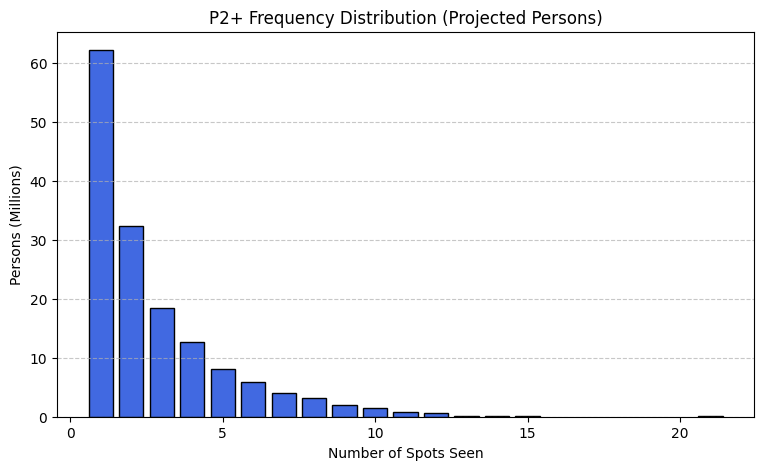

Share of impressions at 5+ exposures: 0.444


In [34]:
person_counts = exposures.groupby('respondent_id').size().reset_index(name='n')
person_counts['mw'] = person_counts['respondent_id'].map(monthly_weights)
freq_dist = person_counts.groupby('n')['mw'].sum().reset_index()
freq_dist['persons_m'] = freq_dist['mw'] / 1e6

plt.figure(figsize=(9, 5))
plt.bar(freq_dist['n'], freq_dist['persons_m'], color='royalblue', edgecolor='black')
plt.title('P2+ Frequency Distribution (Projected Persons)')
plt.xlabel('Number of Spots Seen')
plt.ylabel('Persons (Millions)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# share of impressions going to people with 5+ exposures
n_by_person = exposures.groupby('respondent_id')['ad_airing_id'].transform('size')
share_5plus = exposures.loc[n_by_person >= 5, 'weight'].sum() / exposures['weight'].sum()
print(f"Share of impressions at 5+ exposures: {share_5plus:.3f}")

**Answer:** No. The average frequency is 3.0, but the distribution is skewed to the right (see the plot): most of the reached people saw only a few spots, while a smaller group of heavy viewers saw many. People with 5 or more exposures receive 0.444 of all impressions. The average hides both ends: light viewers who are under-exposed and heavy viewers who are over-exposed. The full distribution describes the campaign better than one average.

## Task 2.3 — On target?

In [35]:
by_net = brand_a_priced.groupby('network_code')[['imp_p2', 'imp_a18']].sum()
by_net['target_share'] = by_net['imp_a18'] / by_net['imp_p2']
display(by_net.sort_values('target_share').style.format(
    {'imp_p2': '{:,.0f}', 'imp_a18': '{:,.0f}', 'target_share': '{:.3f}'}))

share_target = a18_imp_m / p2_imp_m
print(f"Share of impressions on A18-49: {share_target:.3f}")

,imp_p2,imp_a18,target_share
network_code,,,
FNC,"57,798,841","2,717,037",0.047
CBS,"88,980,316","13,693,421",0.154
ABC,"94,211,430","16,988,998",0.180
NBC,"41,435,020","7,833,538",0.189
HIST,"12,329,303","2,484,757",0.202
FOX,"76,255,700","18,440,098",0.242
HGTV,"24,657,356","7,554,439",0.306
FOOD,"9,481,466","2,991,886",0.316
BRAVO,"5,084,258","2,817,365",0.554


Share of impressions on A18-49: 0.194


**Answer:** Only 0.194 of the impressions landed on A18–49, while the target is about 0.42 of the population, so the campaign under-delivered against its target. The table by network shows why: the lowest target shares are on FNC (0.047), CBS (0.154), ABC (0.180) and NBC (0.189), and the highest on FX (0.651) and BRAVO (0.554). All five big networks are below 0.25, yet they carry about 86% of P2+ impressions (358.7M of 418.8M) and about 93% of the budget. FNC is the biggest problem: 40 spots, but its audience is very old.

## Task 3.1 — Cost

In [36]:
total_cost = brand_a_priced['cost_usd'].sum()
cpm_p2 = total_cost / (p2_imp_m * 1e6) * 1000
cpp_p2 = total_cost / p2_grps
cpm_a18 = total_cost / (a18_imp_m * 1e6) * 1000
cpp_a18 = total_cost / a18_grps

print(f"Campaign cost (USD): {int(round(total_cost))}")
print(f"P2+ CPM (USD): {cpm_p2:.2f}")
print(f"P2+ CPP (USD): {int(round(cpp_p2))}")
print(f"A18-49 CPM (USD): {cpm_a18:.2f}")
print(f"A18-49 CPP (USD): {int(round(cpp_a18))}")

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


## Task 3.2 — By network

In [37]:
net_perf = brand_a_priced.groupby('network_code').agg(
    spots=('ad_airing_id', 'count'), cost_usd=('cost_usd', 'sum'),
    imp_p2=('imp_p2', 'sum'), imp_a18=('imp_a18', 'sum')).reset_index()
net_perf['cpm_p2'] = net_perf['cost_usd'] / net_perf['imp_p2'] * 1000
net_perf['cpm_a18'] = net_perf['cost_usd'] / net_perf['imp_a18'] * 1000
display(net_perf.style.format({'cost_usd': '${:,.0f}', 'imp_p2': '{:,.0f}', 'imp_a18': '{:,.0f}',
                               'cpm_p2': '${:.2f}', 'cpm_a18': '${:.2f}'}))

,network_code,spots,cost_usd,imp_p2,imp_a18,cpm_p2,cpm_a18
0,ABC,29,"$1,625,700","94,211,430","16,988,998",$17.26,$95.69
1,BRAVO,33,"$49,610","5,084,258","2,817,365",$9.76,$17.61
2,CBS,22,"$1,488,700","88,980,316","13,693,421",$16.73,$108.72
3,FNC,40,"$526,300","57,798,841","2,717,037",$9.11,$193.70
4,FOOD,33,"$96,620","9,481,466","2,991,886",$10.19,$32.29
5,FOX,13,"$2,434,700","76,255,700","18,440,098",$31.93,$132.03
6,FX,38,"$92,200","8,522,567","5,551,130",$10.82,$16.61
7,HGTV,39,"$230,000","24,657,356","7,554,439",$9.33,$30.45
8,HIST,37,"$79,640","12,329,303","2,484,757",$6.46,$32.05
9,NBC,16,"$796,800","41,435,020","7,833,538",$19.23,$101.72


**Answer:** The money went almost entirely to the five big networks: about USD 6.87M of USD 7.42M (93%). FOX alone took USD 2.43M for only 13 spots, followed by ABC (USD 1.63M) and CBS (USD 1.49M). The five small networks cost only about USD 0.55M together. For the whole audience the cheapest network is HIST (P2+ CPM USD 6.46). For the target the cheapest are FX (A18–49 CPM USD 16.61) and BRAVO (USD 17.61), and the most expensive is FNC (USD 193.70). FNC looks cheap for P2+ (CPM USD 9.11), but its audience is far older than the target, so it is the worst buy for A18–49.

## Task 3.3 — Guarantee

In [38]:
guaranteed_grps = 150.0
guarantee_met = p2_grps >= guaranteed_grps
make_good_grps = max(0.0, guaranteed_grps - p2_grps)
make_good_val = make_good_grps * cpp_p2

print("Guarantee met:", guarantee_met)
print(f"Make-good GRPs owed: {make_good_grps:.1f}")
print(f"Value of make-goods (USD): {int(round(make_good_val))}")

Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012869


## Task 4 — Do networks add up?

In [39]:
big_nets = ['CBS', 'NBC', 'ABC', 'FOX', 'FNC']
small_nets = ['FX', 'BRAVO', 'HGTV', 'FOOD', 'HIST']

spots_big = set(brand_a_priced[brand_a_priced['network_code'].isin(big_nets)]['ad_airing_id'])
spots_small = set(brand_a_priced[brand_a_priced['network_code'].isin(small_nets)]['ad_airing_id'])

viewers_big = set(exposures[exposures['ad_airing_id'].isin(spots_big)]['respondent_id'])
viewers_small = set(exposures[exposures['ad_airing_id'].isin(spots_small)]['respondent_id'])
viewers_both = viewers_big & viewers_small
viewers_all = viewers_big | viewers_small

def reach(ids):
    return sum(monthly_weights[r] for r in ids) / pop_monthly_p2 * 100

reach_big, reach_small, reach_whole = reach(viewers_big), reach(viewers_small), reach(viewers_all)
overlap_actual = reach(viewers_both)
overlap_expected = reach_big * reach_small / 100.0

added_pts = reach_whole - reach_big
cost_small = brand_a_priced[brand_a_priced['network_code'].isin(small_nets)]['cost_usd'].sum()
cost_big = brand_a_priced[brand_a_priced['network_code'].isin(big_nets)]['cost_usd'].sum()

print(f"Reach, big networks (%): {reach_big:.1f}")
print(f"Reach, small networks (%): {reach_small:.1f}")
print(f"Reach, whole campaign (%): {reach_whole:.1f}")
print(f"Overlap (%): {overlap_actual:.1f}")
print(f"Overlap if independent (%): {overlap_expected:.1f}")
print(f"Reach added by small networks (points): {added_pts:.1f}")
print(f"Cost per added reach point, small (USD): {int(round(cost_small / added_pts))}")
print(f"Cost per reach point, big (USD): {int(round(cost_big / reach_big))}")

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456


**Answer:** Reach does not add because the same person can watch big and small networks, and the whole campaign counts that person once: 39.8 + 12.4 − 8.7 = 43.5. The actual overlap (8.7%) is larger than the 4.9% expected if the two audiences were independent. About 70% of the small-network reach (8.7 of 12.4) was also reached by the big networks, against 39.8% for the whole population, so viewers of small networks are more likely than average to have been reached by the big ones too. A likely reason is that they are heavy TV viewers who watch many channels. The small networks added only 3.7 points of reach, at about USD 148.7K per added point against about USD 172.5K per point on the big networks. The added reach was slightly cheaper, but small. The real value of the small networks is their low cost per target impression (A18–49 CPM of USD 17–32 for FX, BRAVO, HGTV, FOOD and HIST against USD 96–194 for the big ones), not new reach.

## Task 5 — How sure are we?

In [40]:
panelists = exposures.groupby('ad_airing_id')['respondent_id'].nunique()
brand_a_priced['panelists_cnt'] = brand_a_priced['ad_airing_id'].map(panelists).fillna(0).astype(int)

p = brand_a_priced['rating_p2'] / 100.0
n = brand_a_priced['broadcast_date'].map(daily_n_p2)
brand_a_priced['se_p2'] = np.sqrt(p * (1 - p) / n) * 100.0
brand_a_priced['rel_se'] = np.where(brand_a_priced['rating_p2'] > 0,
                                    brand_a_priced['se_p2'] / brand_a_priced['rating_p2'], np.nan)

net_quality = brand_a_priced.groupby('network_code').agg(
    median_panelists=('panelists_cnt', 'median'),
    median_rel_se=('rel_se', 'median')).reset_index()
display(net_quality.style.format({'median_panelists': '{:.1f}', 'median_rel_se': '{:.3f}'}))

zero_panelist_spots = (brand_a_priced['panelists_cnt'] == 0).sum()
med_rel_se_big = brand_a_priced[brand_a_priced['network_code'].isin(big_nets)]['rel_se'].median()
med_rel_se_small = brand_a_priced[brand_a_priced['network_code'].isin(small_nets)]['rel_se'].median()

spots_with_w1834 = set(exposures[exposures['respondent_id'].isin(w18_34_ids)]['ad_airing_id'])
w1834_zero_cells = brand_a_priced['ad_airing_id'].nunique() - len(spots_with_w1834)

print("Duplicate exposure rows:", exposures.duplicated(['ad_airing_id', 'respondent_id']).sum())  # must be 0
print("Spots seen by no panelist:", zero_panelist_spots)
print(f"Median relative SE, big networks: {med_rel_se_big:.3f}")
print(f"Median relative SE, small networks: {med_rel_se_small:.3f}")
print("W18-34 zero-cell spots:", w1834_zero_cells)

,network_code,median_panelists,median_rel_se
0,ABC,57.0,0.123
1,BRAVO,3.0,0.540
2,CBS,69.0,0.113
3,FNC,31.0,0.164
4,FOOD,5.0,0.423
5,FOX,145.0,0.080
6,FX,5.5,0.423
7,HGTV,11.0,0.301
8,HIST,5.0,0.460
9,NBC,68.5,0.115


Duplicate exposure rows: 0
Spots seen by no panelist: 10
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171


**Answer:** 10 spots were seen by no panelist, so their rating is 0.0. This does not mean nobody watched: it means nobody in the panel did. The small networks have a median of only 3–11 panelists per spot (BRAVO 3, FOOD 5, HIST 5, FX 5.5, HGTV 11) against 31–145 for the big ones, and a median relative standard error of 0.417 against 0.122. These errors are a lower bound, because a weighted panel behaves like a smaller random sample. For W18–34, 171 of the 300 spots (57%) are zero-cells. If the client asked for the W18–34 rating by spot, I would tell them it cannot be reported: more than half of the spots would show 0 and the rest rest on one or two panelists. The campaign should be judged in aggregate, by network, week or daypart, where the sample is large enough.

## Bonus

In [42]:
dp = brand_a_priced.groupby(['network_code', 'daypart']).agg(
    spots=('ad_airing_id', 'count'), cost=('cost_usd', 'sum'), imp_a18=('imp_a18', 'sum'))
dp['cpm_a18'] = dp['cost'] / dp['imp_a18'].replace(0, np.nan) * 1000
dp = dp[dp['spots'] >= 3].dropna()          # ignore thin cells

display(dp.sort_values('cpm_a18', ascending=False).head(5))   # worst for the target
display(dp.sort_values('cpm_a18').head(5))                    # best for the target

# 20 spots to move: the four worst cells (9 + 3 + 4 + 4 = 20 spots)
bad_cells = [('FNC', 'Daytime News'), ('FNC', 'Early Evening'), ('CBS', 'Daytime'), ('FNC', 'Prime Opinion')]
mask = pd.MultiIndex.from_frame(brand_a_priced[['network_code', 'daypart']]).isin(bad_cells)
moved = brand_a_priced[mask]
moved_cost, old_imp = moved['cost_usd'].sum(), moved['imp_a18'].sum()

# replace them spot for spot (20 new spots) in well-sampled cheap cells at their average spot cost and spot impressions
new_cells = {('FX', 'Daytime Movies'): 10, ('HGTV', 'Early Fringe'): 5, ('BRAVO', 'Late Fringe'): 5}
new_cost = sum(n * dp.loc[k, 'cost'] / dp.loc[k, 'spots'] for k, n in new_cells.items())
new_imp = sum(n * dp.loc[k, 'imp_a18'] / dp.loc[k, 'spots'] for k, n in new_cells.items())

tot_imp = brand_a_priced['imp_a18'].sum()
after_cost = total_cost - moved_cost + new_cost
after_imp = tot_imp - old_imp + new_imp

print("Spots moved:", len(moved), "| budget removed (USD):", int(moved_cost), "| new spots cost (USD):", int(new_cost))
print("A18-49 impressions (M): before", round(tot_imp / 1e6, 1), "after", round(after_imp / 1e6, 1))
print("Campaign cost (USD): before", int(total_cost), "after", int(after_cost))
print("A18-49 CPM (USD): before", round(cpm_a18, 2), "after", round(after_cost / after_imp * 1000, 2))

spots      cost   imp_a18     cpm_a18
network_code daypart                                             
FNC          Daytime News       9  101700.0  218057.0  466.391815
             Early Evening      3   61500.0  166106.0  370.245506
CBS          Daytime            4  118000.0  424166.0  278.192972
FNC          Prime Opinion      4  159600.0  676760.0  235.829541
             Weekend           11  111100.0  673031.0  165.074120

spots     cost    imp_a18    cpm_a18
network_code daypart                                                     
HGTV         Late Night & Overnight      4   1800.0   490285.0   3.671334
FX           Daytime Movies             25  27500.0  2311756.0  11.895719
HGTV         Early Fringe                4  17600.0  1463922.0  12.022498
BRAVO        Weekend Marathon            6   5220.0   412179.0  12.664401
             Late Fringe                 9   7830.0   512173.0  15.287803

Spots moved: 20 | budget removed (USD): 440800 | new spots cost (USD): 37350
A18-49 impressions (M): before 81.1 after 82.6
Campaign cost (USD): before 7420270 after 7016820
A18-49 CPM (USD): before 91.53 after 84.92


**Answer:** I propose moving 20 spots from the four most expensive cells for the target, FNC Daytime News, FNC Early Evening, CBS Daytime and FNC Prime Opinion (A18–49 CPM of USD 236–466 against USD 91.53 for the whole campaign), to 20 spots on FX Daytime Movies (10), HGTV Early Fringe (5) and BRAVO Late Fringe (5), where the A18–49 CPM is only USD 12–15. This removes USD 440,800 of budget, and the 20 new spots cost USD 37,350. A18–49 impressions rise from 81.1M to 82.6M, the campaign cost falls from USD 7,420,270 to USD 7,016,820, and the A18–49 CPM falls from USD 91.53 to USD 84.92. The freed budget of about USD 403K could buy even more target impressions. The caveat is that the estimate assumes the new spots deliver the same average audience as today's spots in these dayparts, and the small-network numbers rest on very few panelists (3–11 per spot), so the real effect is uncertain.